# 02 · A CNN From Scratch: The Baseline
**Course Modules 2 (Build a model: classification) and 3 (Model design: building blocks, parameters, tensor shapes)**

**Strategy, why this step comes first:** before using any big pretrained model, we build the simplest working classifier ourselves.
1. It gives a **baseline**: every later improvement is measured against this number.
2. Building it by hand shows exactly what a CNN is: every layer, every tensor shape, every parameter.
3. It is the first measurement of the **lab-to-field gap** with our own code.

| You will learn | Where it is in the code |
|---|---|
| CNN building blocks: Conv → BatchNorm → ReLU → MaxPool | `models.conv_block` |
| How tensor shapes change layer by layer | section 2 |
| How to count parameters by hand | section 3 |
| A full training loop (loss, optimizer, schedule, mixed precision) | `train.fit` |

In [1]:
import torch, numpy as np, pandas as pd, matplotlib.pyplot as plt
from torchinfo import summary
from lab_to_field.config import CLASSES, N_CLASSES, FIGURES_DIR
from lab_to_field.models import SimpleCNN, count_params
from lab_to_field.train import TrainConfig
from lab_to_field.experiment import run, splits
plt.rcParams["figure.dpi"] = 110
print("GPU:", torch.cuda.get_device_name(0))

GPU: NVIDIA GeForce RTX 4050 Laptop GPU


## 1. The building blocks (concept)

| Block | What it does, in simple words | Why we need it |
|---|---|---|
| **Convolution (3×3)** | Slides a small 3×3 filter over the image; each filter learns to detect one pattern (an edge, a spot, a color change) | Finds local patterns anywhere in the image, using few parameters (weight sharing) |
| **Batch Normalization** | Rescales each channel to mean ≈ 0, std ≈ 1 over the batch, then applies a learned scale and shift | Training is faster and more stable |
| **ReLU** activation | `max(0, x)`: keeps positive values, zeroes negative ones | Without a non-linearity, stacked layers collapse into one linear function |
| **MaxPool (2×2)** | Keeps the largest value in each 2×2 window, so height and width halve | Fewer computations, and each later filter "sees" a bigger area (receptive field) |
| **Global Average Pooling** | Averages each channel over the whole image → one number per channel | Turns the feature map into a vector, whatever the image size |
| **Dropout** | Randomly zeroes 30% of features during training | Regularization: stops the model relying on a single feature |
| **Linear (fully connected)** | Multiplies the feature vector by a weight matrix → one score (logit) per class | Final decision |

Our network = 4 × [Conv → BN → ReLU → MaxPool] → GAP → Dropout → Linear.
Channels double at every block (32 → 64 → 128 → 256) while the image halves. This is the classic CNN pattern: **less "where", more "what"**.

## 2. Tensor shapes, layer by layer
A batch of images is a 4-D tensor: **(batch, channels, height, width)**. One 224×224 colour photo = `(1, 3, 224, 224)`.

In [2]:
model = SimpleCNN(N_CLASSES)
x = torch.randn(1, 3, 224, 224)
print(f"{'layer':<12}{'output shape':<22}")
print(f"{'input':<12}{str(tuple(x.shape)):<22}")
for i, block in enumerate(model.features):
    x = block(x)
    print(f"{'block ' + str(i + 1):<12}{str(tuple(x.shape)):<22}")
x = model.pool(x);  print(f"{'GAP':<12}{str(tuple(x.shape)):<22}")
x = model.head(x);  print(f"{'linear':<12}{str(tuple(x.shape)):<22}  <- one score per class ({N_CLASSES})")

layer       output shape          
input       (1, 3, 224, 224)      
block 1     (1, 32, 112, 112)     
block 2     (1, 64, 56, 56)       
block 3     (1, 128, 28, 28)      
block 4     (1, 256, 14, 14)      
GAP         (1, 256, 1, 1)        
linear      (1, 28)                 <- one score per class (28)


**Read it:** each block halves height and width (224 → 112 → 56 → 28 → 14) and grows the channels. GAP collapses 256×14×14 into 256 numbers, and the linear layer maps those 256 numbers to 28 class scores.

## 3. Counting parameters by hand

| Layer type | Formula | Example from our network |
|---|---|---|
| Conv k×k, no bias | k · k · C_in · C_out | block 1: 3·3·3·32 = **864** |
| BatchNorm | 2 · C (scale γ and shift β) | block 1: 2·32 = **64** |
| Linear | in · out + out (bias) | 256·28 + 28 = **7,196** |

ReLU, MaxPool, GAP and Dropout have **no** parameters.

In [3]:
def by_hand(chs=(3, 32, 64, 128, 256), n_classes=N_CLASSES):
    conv = sum(3 * 3 * a * b for a, b in zip(chs[:-1], chs[1:]))
    bn = sum(2 * c for c in chs[1:])
    linear = chs[-1] * n_classes + n_classes
    return conv, bn, linear

conv, bn, linear = by_hand()
total, trainable = count_params(model)
print(f"conv {conv:,} + batchnorm {bn:,} + linear {linear:,} = {conv + bn + linear:,}")
print(f"PyTorch count: {total:,}  -> match: {total == conv + bn + linear}")
summary(model, input_size=(1, 3, 224, 224), col_names=("output_size", "num_params", "mult_adds"), depth=2)

conv 387,936 + batchnorm 960 + linear 7,196 = 396,092
PyTorch count: 396,092  -> match: True


Layer (type:depth-idx)                   Output Shape              Param #                   Mult-Adds
SimpleCNN                                [1, 28]                   --                        --
├─Sequential: 1-1                        [1, 256, 14, 14]          --                        --
│    └─Sequential: 2-1                   [1, 32, 112, 112]         928                       43,352,128
│    └─Sequential: 2-2                   [1, 64, 56, 56]           18,560                    231,211,136
│    └─Sequential: 2-3                   [1, 128, 28, 28]          73,984                    231,211,264
│    └─Sequential: 2-4                   [1, 256, 14, 14]          295,424                   231,211,520
├─AdaptiveAvgPool2d: 1-2                 [1, 256, 1, 1]            --                        --
├─Sequential: 1-3                        [1, 28]                   --                        --
│    └─Flatten: 2-5                      [1, 256]                  --                        -

**Takeaways:**
- The whole model has only ~0.4 M parameters (ResNet-50 has 25 M). It is tiny, fast, and easy to understand.
- Almost all parameters sit in the last conv blocks, where channels are largest (cost grows with C_in × C_out).
- `mult_adds` (MACs) measures compute: the first blocks are cheap in parameters but expensive in compute, because the feature maps are big.

## 4. Train it (lab data only)

**Training recipe** (each choice is studied properly in notebook 05):
- **Loss:** cross-entropy, the standard for single-label classification
- **Optimizer:** AdamW (Adam with decoupled weight decay)
- **Learning rate schedule:** short warm-up, then cosine decay (`OneCycleLR`)
- **Mixed precision (fp16):** about 2× faster on the GPU, with the same accuracy
- **Model selection:** keep the epoch with the best *PlantVillage validation* accuracy. Field data is never looked at.
- **Data:** at most 500 lab photos per class (~13 k photos), basic augmentation (random crop + flips)

In [4]:
cfg = TrainConfig(name="02_simple_cnn", model="simple_cnn", epochs=12, lr=3e-3, augment="basic", batch_size=64)
res = run(cfg, track="lab")

[02_simple_cnn] loaded saved result (delete 02_simple_cnn.json or pass force=True to retrain): lab acc 0.958 | field val 0.071 | field test 0.089


,n,accuracy,macro_f1,mean_confidence,ece
Lab test (PlantVillage),3781,0.958212,0.95733,0.923318,0.034894
Field test (PlantDoc),236,0.088983,0.079225,0.776701,0.689938


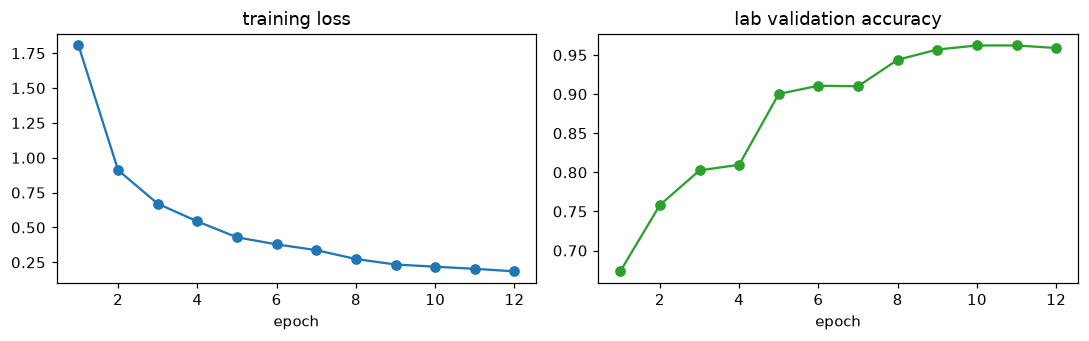

In [5]:
h = pd.DataFrame(res["history"])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.2))
a1.plot(h.epoch, h.train_loss, marker="o"); a1.set_title("training loss"); a1.set_xlabel("epoch")
a2.plot(h.epoch, h.val_acc, marker="o", color="tab:green"); a2.set_title("lab validation accuracy"); a2.set_xlabel("epoch")
plt.tight_layout(); fig.savefig(FIGURES_DIR / "02_training_curves.png", bbox_inches="tight")

lab, field = res["lab_test"], res["field_test"]
table = pd.DataFrame({"Lab test (PlantVillage)": lab, "Field test (PlantDoc)": field}).T
table[["n", "accuracy", "macro_f1", "mean_confidence", "ece"]].round(3)

field 95% confidence interval: 5.5% to 12.7%


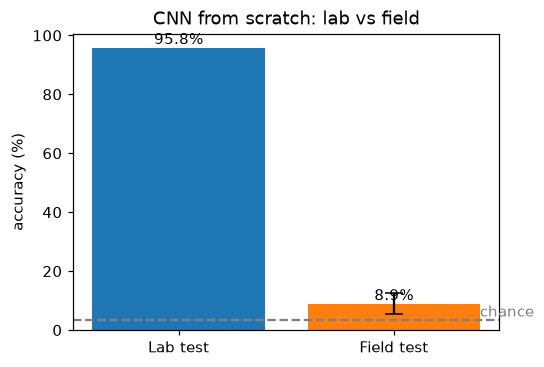

In [6]:
fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(["Lab test", "Field test"], [lab["accuracy"] * 100, field["accuracy"] * 100], color=["tab:blue", "tab:orange"])
ax.axhline(100 / N_CLASSES, ls="--", c="grey"); ax.text(1.4, 100 / N_CLASSES + 1, "chance", color="grey")
lo, hi = field["accuracy_ci95"]
ax.errorbar(1, field["accuracy"] * 100, yerr=[[field["accuracy"] * 100 - lo * 100], [hi * 100 - field["accuracy"] * 100]], c="k", capsize=6)
ax.bar_label(bars, fmt="%.1f%%"); ax.set_ylabel("accuracy (%)"); ax.set_title("CNN from scratch: lab vs field")
fig.savefig(FIGURES_DIR / "02_gap.png", bbox_inches="tight")
print(f"field 95% confidence interval: {lo:.1%} to {hi:.1%}")

## 5. What the result means

- **Lab:** the scratch CNN learns PlantVillage well. A high score is easy here, partly because of the background shortcut found in notebook 01.
- **Field:** accuracy collapses on real photos. This reproduces the published lab-to-field gap with our own code.
- **Confidence vs accuracy:** compare `mean_confidence` with `accuracy` on the field test. When the model is much more confident than it is accurate, it is **overconfident**, and `ece` (expected calibration error) measures that gap. We fix this in notebook 05.

**Decision:** a small network trained from zero on 13 k lab photos cannot learn features that transfer to the field.
→ Next step (notebook 03): start from networks **pretrained** on millions of varied photos (transfer learning).

### Our results
| | Lab test (PlantVillage) | Field test (PlantDoc) |
|---|---|---|
| Accuracy | **95.8%** | **8.9%** (95% CI 5.5–12.7%) |
| Mean confidence | 92% | **78%** |
| ECE (calibration error) | 0.03 | **0.69** |

- On field photos the scratch CNN is barely above chance (3.6%), yet it is still **78% confident**. It is not just wrong, it is *confidently* wrong.
- This is the whole problem in one table, reproduced with our own code: lab accuracy says "solved", the field says "not even close".

## Review questions
1. Write the output shape after each block for a 224×224 input. Why does height halve?
2. How many parameters does a 3×3 conv from 64 to 128 channels have? (73,728 without bias)
3. Why does ReLU have no parameters? Why do we need it at all?
4. What does Global Average Pooling replace, and why is it better than flattening a 256×14×14 map?
5. Why do we choose the best epoch on validation data, and not on the field test?
6. What is the difference between parameters and MACs?